In [1]:
import os
import numpy as npx
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

## UMAP

In [ ]:
path = r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv-test\output.csv"
df = pd.read_csv(path)
df.head()

In [ ]:
path = r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv\save_for_paper\masked_ratio_means-wide.csv"
df = pd.read_csv(path)
col_groups = {
    "ORR": ["Redox"],
    "CAR" :[
        "Positive_Ion_3",
        "Positive_Ion_4",
        "Positive_Ion_5"
    ],
    "CL" : [
        "Negative_Ion_33", #1447.965 CL 72:8 (-H),
        "Negative_Ion_34",# 1469.9493 CL 74:11 (-H)
    ],
    "LPL" : [
        "Negative_Ion_1",
        "Negative_Ion_3",
        "Positive_Ion_7",
    ],
    "PL (Sat)" :[
        "Positive_Ion_11",
        "Negative_Ion_7",
        "Negative_Ion_18",
    ],
    "PL (MUFA)":[
        "Positive_Ion_14",
        "Positive_Ion_18",
        "Negative_Ion_5",
        "Negative_Ion_17",
        "Negative_Ion_21",   
    ] ,
    "PL (AA)":[
        "Negative_Ion_8",
        "Negative_Ion_10",
        "Negative_Ion_11",
        "Negative_Ion_12",
        "Negative_Ion_14",
        "Negative_Ion_19",
        "Negative_Ion_23",
        "Positive_Ion_15",
        "Positive_Ion_16",
        "Positive_Ion_21",
    ],
    "PL (DHA)":[
        "Negative_Ion_9",
        "Negative_Ion_15",
    ],
    "PL (PUFA)":[
        "Positive_Ion_19",
        "Positive_Ion_20",
        "Negative_Ion_26",
        "Negative_Ion_30",
        "Negative_Ion_31",
    ],
    "Lipid Unsat.": ["Lipid_Unsaturation"],
    "SM":[
        "Positive_Ion_9",
        "Positive_Ion_13",
        "Positive_Ion_22",
        "Positive_Ion_23",
        "Positive_Ion_24",
        "Positive_Ion_25",
        "Negative_Ion_4"
    ],
            "SHexCer" : [
        "Negative_Ion_22",
        "Negative_Ion_24",
        "Negative_Ion_27",
        "Negative_Ion_28",
        "Negative_Ion_29",
        "Negative_Ion_32"
    ],

        "Fib. Collagen": [
        # 'Collagen',
        "Collagen_Thickness",
        "Collagen_Coherence"
    ],

}
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

df = df[df['Source_ID']=='S21']

for new_col, source_cols in col_groups.items():
    df[new_col] = df[source_cols].mean(axis=1)

unit_order = [
      "Cluster1",
      "Cluster2",
      "Cluster4",
      "Cluster5",
      "Cluster6",
      "Cluster7",
      "Cluster9",
    #   "Cluster10",
      "Cluster11",
      "Cluster13",
      "Cluster15",
      "Cluster16",
      "Cluster17",
      "Cluster18",
      "Cluster19",
      "Cluster20",
      "Cluster21",
      "Cluster23",
      "Cluster24",
      "Cluster25",
      "Cluster26"
    ]
group_order = ['C1', 'C2', 'C3', 'CM', "M"]

# group_order = [
#     'Outer Cortex', 
#     'Middle Cortex', 
#     'Juxtamedullary Cortex', 
#     'Outer Stripe', 
#     'Inner Stripe',
#     'Inner Medulla'
#     ]

group_map ={
    'C1': 'Outer Cortex',
    'C2': 'Inner Cortex',
    'C3': 'CM Boundary',
    'CM': 'Outer Stripe',
    'M': 'Inner Stripe'
}

# df['Unit'] = pd.Categorical(df['Unit'], categories=unit_order, ordered=True)
# df['Group_ID'] = pd.Categorical(df['Group_ID'], categories=group_order, ordered=True)
for i, val_col in enumerate(df.columns[5:]):
    df[val_col] = df[val_col].fillna(df.groupby(['Group_ID', 'Unit'])[val_col].transform('median'))

df['Group_ID'] = df['Group_ID'].map(group_map)
df = df.fillna(0)

In [43]:
path = r"/Users/jorgevillazon/Library/CloudStorage/OneDrive-UCSanDiego/integrated_pipeline/WSI_data/WSI_data/CODEX_clusters-regions_masks_output_csv-test/output.csv"
df = pd.read_csv(path)
col_groups = {
    # "ORR": ["Redox"],
    "CAR" :[
        "CAR 18:2 (+H)",
        "CAR 18:1 (+H)",
        "CAR 18:0 (+H)"
    ],
    "CL" : [
        "CL 72:8 (-H)", #1447.965 CL 72:8 (-H),
        "CL 74:11 (-H)",# 1469.9493 CL 74:11 (-H)
    ],
    "LPL" : [
        "LPC 16:0 (+H)",
        "LPE 18:0 (-H)",
        "LPI 18:0 (-H)",
    ],
    "PL (Sat)" :[
        "PC 32:0 (+H)",
        "PE 16:0_18:0 (-H)",
        "PI 16:0_18:0 (-H)",
    ],
    "PL (MUFA)":[
        "PC 16:0_18:1 (+H)",
        "PC 18:0_18:1 (+H)",
        "PA 36:1 (-H)",
        "PS 18:0_18:1 (-H)",
        "PI 34:1 (-H)",
        "PI 18:0_18:1 (-H)",   
    ] ,
    "PL (AA)":[
        "PE 16:0_20:4 (-H)",
        "PE 18:1_20:4 (-H)",
        "PE 18:1_20:3 (-H)",
        "PS 16:0_20:4 (-H)",
        "PS 18:0_20:4 (-H)",
        "PI 16:0_20:4 (-H)",
        "PI 18:1_20:3 (-H)",
        "PC 35:4 (+H)",
        "PC 36:5 (+H)",
        "PC 18:0_20:4 (+H)",
    ],
    "PL (DHA)":[
        "PE 16:0_22:6 (-H)",
        "PG 18:1_22:6 (-H)",
    ],
    "PL (PUFA)":[
        "PC O-38:5 (+H)",
        "PC 38:5 (+H)",
        "PC 46:9 (-CH3)",
        "PE 49:9 (-H)",
        "PC 48:9 (-CH3)",
    ],

    "SM":[
        "SM 34:1;2O (+H)",
        "SM 38:1;20 (+H)",
        "SM 42:2;2O (+H)",
        "SM 42:1;2O (+H)",
        "SM 41:0;3O (+H)",
        "SM 42:0;3O (+H)",
        "SM 18:1;2O/16:0 (-CH3)"
    ],
    "SHexCer" : [
        "SHexCer 40:1;3O (-H)",
        "SHexCer 41:1;3O (-H)",
        "SHexCer 42:2;3O (-H)",
        "SHexCer 42:1;3O (-H)",
        "SHexCer 42:0;3O (-H)",
        "SHexCer 50:0;2O (-H)"
    ],
        "Lipid Unsat.": ["Lipid_Unsaturation"],
        "Lipid/Protein" : ["Lipid_to_Protein"],

    # "Fib. Collagen": [
    #     # 'Collagen',
    #     "Collagen_Thickness",
    #     "Collagen_Coherence"
    # ],

}
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# df = df[df['Source_ID']=='S21']

# df = df[df['tissue_id']=='S21-K21_198_3']

for new_col, source_cols in col_groups.items():
    df[new_col] = df[source_cols].mean(axis=1)

unit_order = [
      "Cluster1",
      "Cluster2",
    #   "Cluster3",
      "Cluster4",
      "Cluster5",
      "Cluster6",
      "Cluster7",
      "Cluster8",
      "Cluster9",
    #   "Cluster10",
      "Cluster11",
      "Cluster12",
    #   "Cluster13",
    #   "Cluster14",
      "Cluster15",
      "Cluster16",
      "Cluster17",
      "Cluster18",
      "Cluster19",
      "Cluster20",
      "Cluster21",
      "Cluster22",
      "Cluster23",
      "Cluster24",
      "Cluster25",
      "Cluster26"
    ]
# group_order = ['OC', 'IC', 'CM', 'OS', "IS"]

group_order = [
    'Outer Cortex', 
    'Middle Cortex', 
    'Juxtamedullary Cortex', 
    'Outer Stripe', 
    'Inner Stripe',
    'Inner Medulla'
    ]

# group_map ={
#     'C1': 'Outer Cortex',
#     'C2': 'Inner Cortex',
#     'C3': 'CM Boundary',
#     'CM': 'Outer Stripe',
#     'M': 'Inner Stripe'
# }

# df['mask_name'] = pd.Categorical(df['mask_name'], categories=unit_order, ordered=True)
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)
for i, val_col in enumerate(df.columns[7:]):
    df[val_col] = df[val_col].fillna(df.groupby(['group', 'mask_name'])[val_col].transform('median'))

df[df.columns[7:]] = df[df.columns[7:]].fillna(0)

# df['Group_ID'] = df['Group_ID'].map(group_map)
df.drop(columns=['Redox', 'Collagen_Coherence', 'Collagen_Thickness'],inplace=True)
df = df.replace({'Middle Cortex': 'Outer Cortex', 'Juxtamedullary Cortex': 'Inner Cortex', 'Cluster3':'Cluster4', 'Cluster13': 'Cluster12', 'Cluster14': 'Cluster12', 'Cluster10': 'Cluster9'} )



condition_tdl = (df['mask_name'].isin(['Cluster6', 'Cluster7']) & df['group'].isin(['Outer Cortex', 'Inner Cortex']))
df.loc[condition_tdl, 'group'] = 'Outer Stripe'

condition_pt = (df['mask_name'].isin(['Cluster2', 'Cluster4', 'Cluster5']) & df['group'].isin(['Inner Stripe']))
df.loc[condition_pt, 'group'] = 'Outer Stripe'

condition_tal = (df['mask_name'].isin(['Cluster8', 'Cluster9']) & df['group'].isin(['Inner Medulla']))
df.loc[condition_tal, 'group'] = 'Inner Stripe'

condition_glom = (df['mask_name'].isin(['Cluster1']) & df['group'].isin(['Outer Stripe']))
df.loc[condition_glom, 'group'] = 'Inner Cortex'

/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_7103/1438784588.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df[val_col] = df[val_col].fillna(df.groupby(['group', 'mask_name'])[val_col].transform('median'))
/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_7103/1438784588.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df[val_col] = df[val_col].fillna(df.groupby(['group', 'mask_name'])[val_col].transform('median'))
/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_7103/1438784588.py:143: FutureWarning: The default of observed=False is deprecated and will be changed 

In [ ]:
# import umap 

# from sklearn.preprocessing import StandardScaler
# scaler = StandardScaler().set_output(transform="pandas")
# umap_df = df.copy()
# umap_df[df.columns[7:-13]] = scaler.fit_transform(df[df.columns[7:-13]])
# # umap_df = umap_df.dropna()
# reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
# embedding = reducer.fit_transform(umap_df[df.columns[7:-13]])

# umap_df['umap_1'] = embedding[:, 0]
# umap_df['umap_2'] = embedding[:, 1]
        

In [ ]:
import umap 
umap_df = df.copy()

# feature_cols = df.columns[7:-13]

# q1 = df.groupby('mask_name')[feature_cols].transform('quantile', 0.25)
# q3 = df.groupby('mask_name')[feature_cols].transform('quantile', 0.75)
# iqr = q3 - q1

# # 2. Define outlier boundaries (1.5 * IQR rule)
# lower_bound = q1 - 1.5 * iqr
# upper_bound = q3 + 1.5 * iqr

# # 3. Create a mask where rows must be within bounds for ALL features
# # True if feature is within group bounds, False if it is an outlier
# within_bounds = (df[feature_cols] >= lower_bound) & (df[feature_cols] <= upper_bound)

# # Keep rows where NO feature is an outlier
# clean_df = df[within_bounds.all(axis=1)].copy()

# # 4. Separate features and scale/run UMAP on the cleaned data
# umap_df = clean_df


umap_df[df.columns[7:-13]] = umap_df.groupby('tissue_id')[df.columns[7:-13]].transform(lambda x: (x - x.mean()) / x.std())
# umap_df = umap_df.dropna()
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
embedding = reducer.fit_transform(umap_df[df.columns[7:-13]])

umap_df['umap_1'] = embedding[:, 0]
umap_df['umap_2'] = embedding[:, 1]

In [ ]:
umap_df = pd.read_csv(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv-test\umap-nomid-output.csv")


In [ ]:
umap_df2 = umap_df.replace({'Middle Cortex': 'Outer Cortex', 'Juxtamedullary Cortex': 'Inner Cortex'} )

In [ ]:
import matplotlib.patheffects as pe
import numpy as np
fig, ax = plt.subplots(figsize=(12, 12))

hue_colors={
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    "Cluster3": "#42a84c",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster8": "#AC1481", 
    "Cluster9": "#840a62",
    "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster12": "#09234b",
    "Cluster13": "#0a3b84",
    "Cluster14": "#355483",
    "Cluster15": "#105ac9",
    "Cluster16": "#357fee",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster22": "#ffede4",
    "Cluster23": "#8b3103",
    "Cluster24": "#f85706",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }


umap_df = umap_df.sample(frac=1, random_state=42)
sns.scatterplot(
    data=umap_df,
    x='umap_1', y='umap_2',
    hue='group',
    # palette=hue_colors,
    # hue_order=hue_order_display,
    alpha=0.9,
    edgecolor='w',
    linewidth=0.2,
    s=5,
    ax=ax
)
embeddings = umap_df[["umap_1", "umap_2"]].values
labels = umap_df["group"].values
unique_labels = umap_df["group"].unique()

# 5. Place clean, bold labels at each cluster's median centroid
for label in unique_labels:
    mask = labels == label
    # Using median for both coordinates yields a better geometric center
    centroid_x = np.median(embeddings[mask, 0])
    centroid_y = np.median(embeddings[mask, 1])

    ax.text(
        centroid_x,
        centroid_y,
        label,
        fontsize=12,  # Adjusted to fit 6x6 figure nicely
        fontweight="bold",
        ha="center",
        va="center",
        color="black",
        rotation=90,
        path_effects=[pe.withStroke(linewidth=3, foreground="white")],
        zorder=100,
    )
# Formatting axes
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([])
ax.set_yticklabels([])
sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
ax.tick_params(left=False, bottom=False)

# Remove the default legend (since we have text labels on centroids)
legend = ax.get_legend()
# if legend is not None:
#     legend.remove()
# plt.savefig(os.path.join(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\plots_CODEX_clusters-regions_masks", "lipids-nomid-UMAP.png"), dpi=300, transparent=True)

In [ ]:
leg = plt.legend
fill_colors = [handle.get_facecolor()[0] for handle in leg.legendHandles]

In [ ]:
umap_df2.to_csv(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv-test\umap-nomid-output.csv", index=False)

## Region Gradients

/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_7103/1913667042.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])[val_col].agg(['mean', 'count']).reset_index()
/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_7103/1913667042.py:74: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')
/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_7103/1913667042.py:73: FutureWarning: The default of observed=False is deprecated and will be changed 

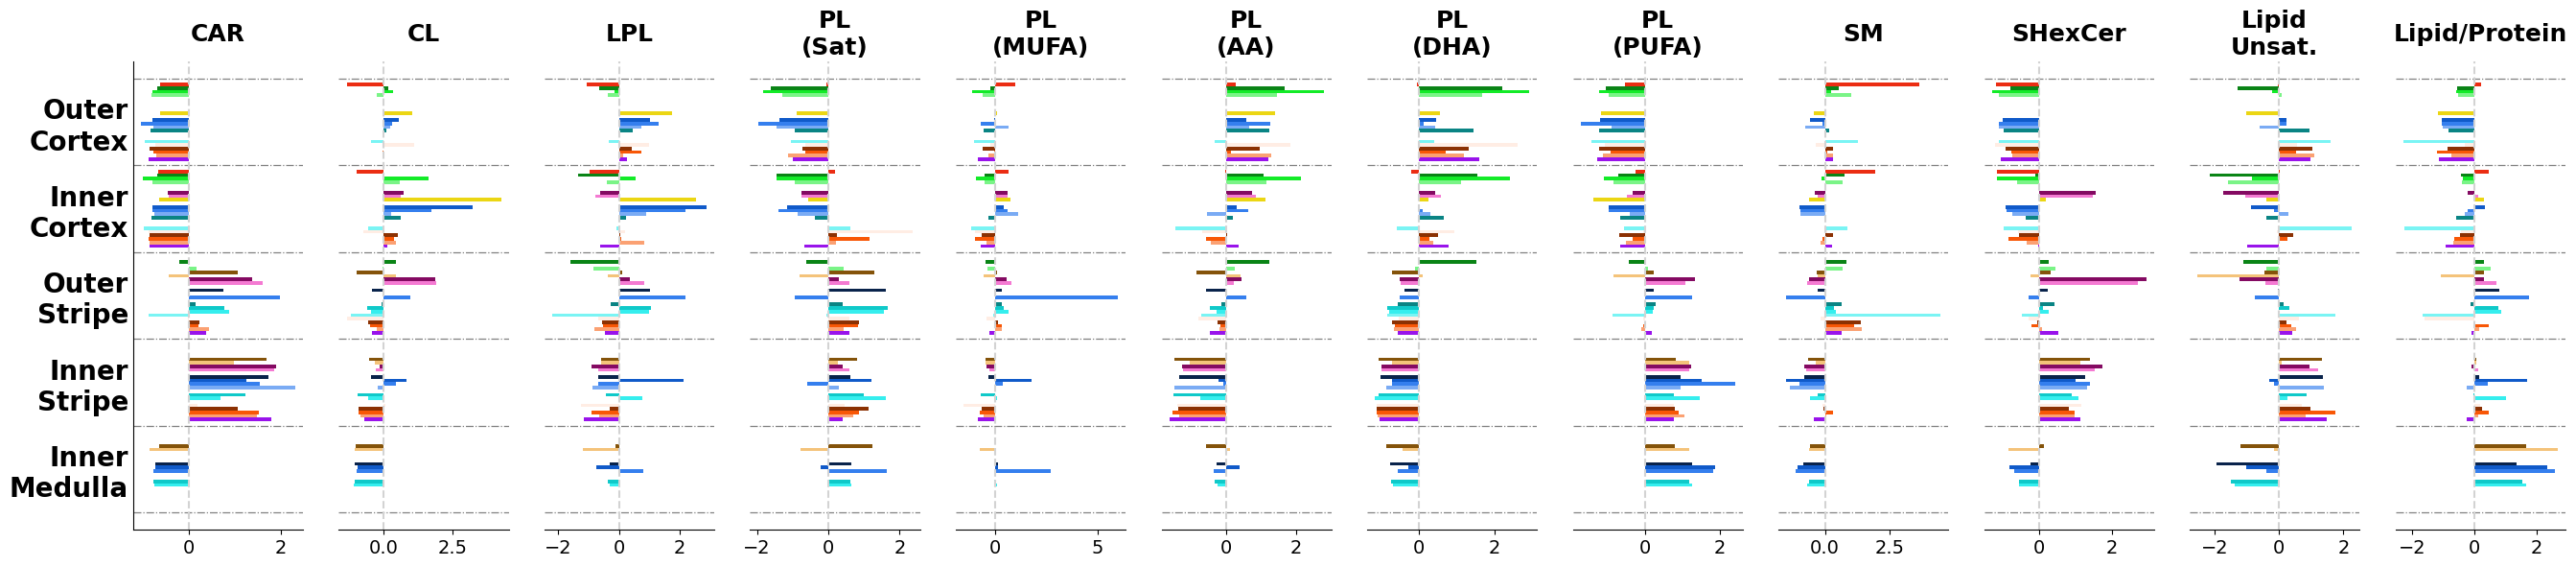

In [44]:
import numpy as np
df = df.replace({'Middle Cortex': 'Outer Cortex', 'Juxtamedullary Cortex': 'Inner Cortex', 'Cluster3':'Cluster4', 'Cluster13': 'Cluster12', 'Cluster14': 'Cluster12', 'Cluster10': 'Cluster9'} )

group_order = ['Outer Cortex', 'Inner Cortex', 'Outer Stripe', 'Inner Stripe', 'Inner Medulla']

regions = ['Outer\nCortex', 'Inner\nCortex', 'Outer\nStripe', 'Inner\nStripe', 'Inner\nMedulla']

unit_order = [
    "Cluster1",
    "Cluster2",
    #   "Cluster3",
    "Cluster4",
    "Cluster5",
    "Cluster6",
    "Cluster7",
    "Cluster8",
    "Cluster9",
    #   "Cluster10",
    "Cluster11",
    "Cluster12",
    #   "Cluster13",
    #   "Cluster14",
    "Cluster15",
    "Cluster16",
    "Cluster17",
    "Cluster18",
    "Cluster19",
    "Cluster20",
    "Cluster21",
    "Cluster22",
    "Cluster23",
    "Cluster24",
    "Cluster25",
    "Cluster26"
    ]
df['mask_name'] = pd.Categorical(df['mask_name'], categories=unit_order, ordered=True)
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

hue_colors={
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    # "Cluster3": "#42a84c",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster8": "#840a62", 
    "Cluster9": "#f47ad2",
    # "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster12": "#09234b",
    # "Cluster13": "#0a3b84",
    # "Cluster14": "#355483",
    "Cluster15": "#105ac9",
    "Cluster16": "#357fee",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster22": "#ffede4",
    "Cluster23": "#8b3103",
    "Cluster24": "#f85706",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }

fig, ax = plt.subplots(figsize=(2.25*len(col_groups.keys()), 6), ncols=len(col_groups.keys()), nrows=1, sharey=True)

# regions = ['Outer\nCortex', 'Inner\nCortex', 'CM\nBoundary', 'Outer\nStripe', 'Inner\nStripe']
for i, val_col in enumerate(col_groups.keys()):
    item_data_plot = df[['mask_name', 'group', val_col]].replace([np.inf, -np.inf], np.nan).dropna(subset=[val_col]).copy()
    agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])[val_col].agg(['mean', 'count']).reset_index()
    agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')
    agg_data_plot = agg_data_plot[agg_data_plot['count'] / agg_data_plot['unit_total'] >=0.07]
    pivot_df = agg_data_plot.pivot(index='group', columns='mask_name', values='mean')

    z_df = pivot_df.copy().astype(float)
    z_values = z_df.to_numpy(dtype=float)
    z_mean = np.nanmean(z_values)
    z_std = np.nanstd(z_values)
    if np.isnan(z_std) or z_std == 0:
        z_df = z_df - z_mean
    else:
        z_df = (z_df - z_mean) / z_std

    item_abs_max = np.nanmax(np.abs(z_df.to_numpy(dtype=float)))
    if np.isnan(item_abs_max):
        item_abs_max = 0

    inverted_df = z_df.iloc[::-1, ::-1]
    inverted_df.plot(ax=ax[i], kind='barh', xlabel=val_col, width=0.9, color=list(hue_colors.values())[::-1]) 
    # ax[i].set_yticklabels(group_order[::-1],fontsize=14, fontweight='bold')


    ax[i].axvline(0, color='lightgray', linestyle='--')
    ax[i].get_legend().remove() 


    y_ticks = ax[i].get_yticks()

    if i == 0:
        sns.despine(ax=ax[i], top=True, right=True, left=False)
    elif i == len(col_groups.keys()):
        sns.despine(ax=ax[i], top=True, right=False, left=True)
    else:
        sns.despine(ax=ax[i], top=True, right=True, left=True)

    if len(y_ticks) > 1:
        # Calculate the distance between bars
        spacing = y_ticks[1] - y_ticks[0]
        
        # This includes boundary lines below the first bar and above the last bar
        minor_ticks = np.arange(y_ticks[0] - spacing/2, y_ticks[-1] + spacing, spacing)
        ax[i].set_yticks(minor_ticks, minor=True)
        
        # Turn off the major grid (at the ticks) and turn on the minor grid
        ax[i].grid(False, which='major', axis='y')
        ax[i].grid(True, which='minor', axis='y', linestyle='-.', color='gray', linewidth=0.9)
        
    # ax[i].set_xlim(-2, 2)


    ax[i].tick_params(which='both', axis='y', length=0)
    ax[i].tick_params(axis='x', labelsize=14)
    ax[i].set_yticklabels(regions[::-1], fontsize=20, fontweight='bold')
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_title(val_col.replace(" ",'\n'), y=1.04, va='center', fontsize=18, fontweight='bold')

    # ax[i].xaxis.label.set(fontsize=18, fontweight='bold')
plt.tight_layout()
# plt.savefig(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\plots_CODEX_clusters-regions_masks\region_gradient_barplot.png",dpi=300, transparent=True)
plt.show()

In [41]:
df2 = df.copy()
condition_tdl = (df['mask_name'].isin(['Cluster6', 'Cluster7']) & df['group'].isin(['Outer Cortex', 'Inner Cortex']))
df2.loc[condition_tdl, 'group'] = 'Outer Stripe'

condition_pt = (df['mask_name'].isin(['Cluster2', 'Cluster4', 'Cluster5']) & df['group'].isin(['Inner Stripe']))
df2.loc[condition_pt, 'group'] = 'Outer Stripe'

condition_tal = (df['mask_name'].isin(['Cluster8', 'Cluster9']) & df['group'].isin(['Inner Medulla']))
df2.loc[condition_tal, 'group'] = 'Inner Stripe'

condition_glom = (df['mask_name'].isin(['Cluster1']) & df['group'].isin(['Outer Stripe']))
df2.loc[condition_glom, 'group'] = 'Inner Cortex'

In [42]:
df2.groupby(['group', 'mask_name'])['CL'].agg(['mean', 'count']).reset_index().pivot(index='group', columns='mask_name', values='count')



/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_7103/2383582491.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df2.groupby(['group', 'mask_name'])['CL'].agg(['mean', 'count']).reset_index().pivot(index='group', columns='mask_name', values='count')


mask_name,Cluster1,Cluster2,Cluster4,Cluster5,Cluster6,Cluster7,Cluster8,Cluster9,Cluster11,Cluster12,...,Cluster17,Cluster18,Cluster19,Cluster20,Cluster21,Cluster22,Cluster23,Cluster24,Cluster25,Cluster26
group,,,,,,,,,,,,,,,,,,,,,
Outer Cortex,1679,3257,8329,878,0,0,550,1919,1466,154,...,2692,3798,193,156,838,22,1769,156,273,1479
Inner Cortex,900,4801,3029,1067,0,0,1223,4268,598,378,...,1147,3243,170,175,2095,36,2262,358,473,1117
Outer Stripe,0,1495,89,2475,792,329,2258,7350,6,2577,...,533,2069,1366,927,3358,25,2732,306,523,2902
Inner Stripe,8,0,0,0,3261,58,5312,16269,0,6364,...,3759,315,6760,1271,81,18,2924,246,593,8975
Inner Medulla,0,0,0,0,383,180,0,0,0,5256,...,262,132,4256,5431,23,1,656,48,139,358


In [6]:
import numpy as np
df['mask_name'] = pd.Categorical(df['mask_name'], categories=unit_order, ordered=True)
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

item_data_plot = df[['mask_name', 'group', 'Lipid Unsat.']].replace([np.inf, -np.inf], np.nan).dropna(subset=['Lipid Unsat.']).copy()
agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])['Lipid Unsat.'].agg(['mean', 'count']).reset_index()
agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')
agg_data_plot = agg_data_plot[agg_data_plot['count'] / agg_data_plot['unit_total'] >=0.07]
pivot_df = agg_data_plot.pivot(index='group', columns='mask_name', values='mean')


/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_74927/3977316586.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])['Lipid Unsat.'].agg(['mean', 'count']).reset_index()
/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_74927/3977316586.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')


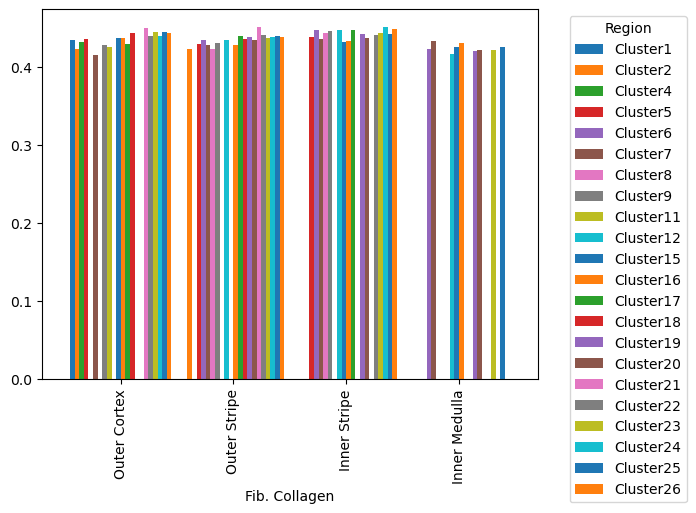

In [7]:

pivot_df.plot(kind='bar', xlabel=val_col, width=0.9) 
legend = plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')

In [6]:
df = df[(df.groupby(['mask_name', 'group'])['mask_name'].transform('size') / df.groupby('mask_name')['mask_name'].transform('size')) * 100 >= 10]

/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_79722/1706368362.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = df[(df.groupby(['mask_name', 'group'])['mask_name'].transform('size') / df.groupby('mask_name')['mask_name'].transform('size')) * 100 >= 10]


In [ ]:
df.groupby(['mask_name', 'group'])['mask_name'].agg(['count'])

/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_79722/4205277275.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  filtered_df.groupby(['mask_name', 'group'])['mask_name'].agg(['count'])


count
mask_name group               
Cluster1  Outer Cortex    1679
          Inner Cortex     850
          Outer Stripe       0
          Inner Stripe       0
          Inner Medulla      0
...                        ...
Cluster9  Outer Cortex       0
          Inner Cortex    4268
          Outer Stripe    7350
          Inner Stripe   16063
          Inner Medulla      0

[110 rows x 1 columns]

In [7]:
import sys 
from pathlib import Path
sys.path.insert(0, os.path.abspath('..'))
from core.hsi_visualizer import HSI_Visualizer

workspace_dir = str(Path.cwd().parent)
wn_1 =2700
wn_2 = 3100
num_samp = 61

visualizer = HSI_Visualizer(
    mol_path=os.path.join(workspace_dir, 'molecule_dataset', 'lipid_subtype_wn_61_test.npz'),
    wavenumber_start=wn_1, wavenumber_end=wn_2, num_samples=num_samp
)

Loading molecules from: /Users/jorgevillazon/Documents/GitHub/hsi_machine_learning/molecule_dataset/lipid_subtype_wn_61_test.npz
HSI Visualizer initialized with 35 molecules.


In [8]:
group_order = ['Outer Cortex', 'Inner Cortex', 'Outer Stripe', 'Inner Stripe', 'Inner Medulla']
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

df.rename(columns={'mask_name':'Unit', 'group': 'Group_ID'}, inplace=True)

items_list = list(df.columns[7:])
output_dir = os.path.join(workspace_dir, 'plots', 'inter_group_unit_boxplots')

unit_colors= {
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    "Cluster3": "#10c922",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster8": "#840a62",
    "Cluster9": "#f47ad2",
    "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster12": "#0a3b84",
    "Cluster13": "#0e52b7",
    "Cluster14": "#0e52b7",
    "Cluster15": "#1369eb",
    "Cluster16": "#478af0",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster22": "#8b3103",
    "Cluster23": "#d44a05",
    "Cluster24": "#f9702a",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }
display_units_boxplots = [
    "Cluster2",
    "Cluster4",
    "Cluster5",
]

unit_display_names = {
    "Cluster1": "Glomeruli | Podo, CD31",
    "Cluster2": "PT | LRP2",
    "Cluster3": "PT | LRP2, AQP1, CD90",
    "Cluster4": "PT | THY1",
    "Cluster5": "PT | PROM1/VCAM1",
    "Cluster6": "TDL | AQP1, Cyto8 (N1)",
    "Cluster7": "TDL | AQP1, Cyto8 (N2)",
    "Cluster8": "TAL | NaK/UMOD",
    "Cluster9": "TAL | UMOD",
    "Cluster10": "TAL | UMOD",
    "Cluster11": "DCT | SLC12a3",
    "Cluster12": "DN | Cyto8 (N1)",
    "Cluster13": "DN | Cyto8",
    "Cluster14": "DN | Cyto8 (N3)",
    "Cluster15": "DN | Cyto8, Bcat",
    "Cluster16": "DN | Cyto8, Bcat, Ecad",
    "Cluster17": "DN | Cyto8, Ecad",
    "Cluster18": "Endothelium | CD31",
    "Cluster19": "Endothelium | CD31, Podo",
    "Cluster20": "Pericytes | CD90, CD31(-)",
    "Cluster21": "VSMCs | aSMA",
    "Cluster22": "Immune | CD20",
    "Cluster23": "Immune - MP | CD45, CD206",
    "Cluster24": "Immune - T | CD3, CD4",
    "Cluster25": "Immune - T | CD3, CD8",
    "Cluster26": "Interstitial cells | IGFBP7"
  }


visualizer.create_individual_barplots(
    df=df, 
    value_col=None,        # Not needed for wide format
    grouping_col=None,     # Signal that we are using Wide format
    items_list=items_list, # The column names
    output_dir=output_dir,
    data_type='Ratio',
    units_to_display=display_units_boxplots,
    consolidate_Group_IDs=True,
    plot_type='violin',
    sig_style='stars_only' if len(display_units_boxplots) > 6 else 'brackets',
    show_plots=False,
    display_name_map=unit_display_names,
    unit_color_map=unit_colors,
    unit_display_map=unit_display_names,
    subgroup_list = group_order,
    remove_outliers=True,
    show_scatter=True,
    show_empty_subgroups=True,
    orientation='vertical'
)

Units to display: ['Cluster2', 'Cluster4', 'Cluster5']
  Saved significance table: /Users/jorgevillazon/Documents/GitHub/hsi_machine_learning/plots/inter_group_unit_boxplots/CAR 18_0 (+H)_significance.csv
  Saved significance table: /Users/jorgevillazon/Documents/GitHub/hsi_machine_learning/plots/inter_group_unit_boxplots/CAR 18_1 (+H)_significance.csv
  Saved significance table: /Users/jorgevillazon/Documents/GitHub/hsi_machine_learning/plots/inter_group_unit_boxplots/CAR 18_2 (+H)_significance.csv
  Saved significance table: /Users/jorgevillazon/Documents/GitHub/hsi_machine_learning/plots/inter_group_unit_boxplots/CL 72_8 (-H)_significance.csv
  Saved significance table: /Users/jorgevillazon/Documents/GitHub/hsi_machine_learning/plots/inter_group_unit_boxplots/CL 74_11 (-H)_significance.csv
  Saved significance table: /Users/jorgevillazon/Documents/GitHub/hsi_machine_learning/plots/inter_group_unit_boxplots/Cer 17_2;2O_8_0;O (+Na)_significance.csv
  Saved significance table: /Users/j

In [ ]:
filtered_df = df[(df.groupby(['mask_name', 'group'])['mask_name'].transform('size') / df.groupby('mask_name')['mask_name'].transform('size')) * 100 >= 70]

In [33]:
group_order = ['Outer Cortex', 'Inner Cortex', 'Outer Stripe', 'Inner Stripe', 'Inner Medulla']

In [34]:

df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

In [35]:
df['group'].unique()

['Inner Stripe', 'Inner Cortex', 'Outer Cortex', 'Outer Stripe', 'Inner Medulla']
Categories (5, object): ['Outer Cortex' < 'Inner Cortex' < 'Outer Stripe' < 'Inner Stripe' < 'Inner Medulla']